In [1]:
import numpy as np
import math
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

In [2]:
moms_height = np.array([162, 175, 163, 170, 175])
dads_height = np.array([173, 170, 175, 180, 185])
child_height = np.array([168, 172, 168, 181, 180])

In [4]:
X = np.column_stack((moms_height, dads_height))
y = child_height
print(X)

[[162 173]
 [175 170]
 [163 175]
 [170 180]
 [175 185]]


In [5]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [8]:
coefficients = model.coef_
intercept = model.intercept_
print(f'Child_heiht = {intercept:.2f} + {coefficients[0]:.2f}*Mom_Height + {coefficients[1]:.2f}* Dad_Height')

Child_heiht = -26.36 + 0.48*Mom_Height + 0.67* Dad_Height


In [9]:
print(intercept + 170 * coefficients[0] + 175 * coefficients[1])

173.20442421867938


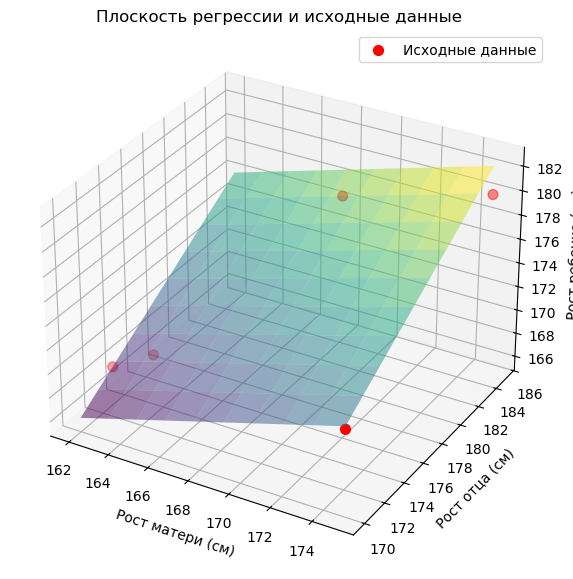

In [12]:
# Создание 3D-графика
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Нанесение исходных точек
ax.scatter(moms_height, dads_height, child_height, c='r', marker='o', s=50, label='Исходные данные')

# Создание сетки для плоскости регрессии
mom_range = np.linspace(moms_height.min(), moms_height.max(), 10)
dad_range = np.linspace(dads_height.min(), dads_height.max(), 10)
mom_grid, dad_grid = np.meshgrid(mom_range, dad_range)

# Расчет предсказаний для каждой точки сетки
child_pred_surface = intercept + coefficients[0] * mom_grid + coefficients[1] * dad_grid

# Построение плоскости регрессии
ax.plot_surface(mom_grid, dad_grid, child_pred_surface, alpha=0.5, cmap='viridis')

# Настройка графика
ax.set_xlabel('Рост матери (см)')
ax.set_ylabel('Рост отца (см)')
ax.set_zlabel('Рост ребенка (см)')
ax.set_title('Плоскость регрессии и исходные данные')
plt.legend()
plt.show()